# QRShield – Simple EDA
We explore two URL datasets: **malicious_phish** and **PhiUSIIL**. Goal: understand the data before training.

In [1]:
import pandas as pd                                    # pandas = tables
import matplotlib.pyplot as plt                        # matplotlib = charts
import kagglehub                                       # download Kaggle datasets
from kagglehub import KaggleDatasetAdapter

In [2]:
# ---- 1. Load datasets directly from Kaggle via kagglehub ----
# Dataset 1: malicious-urls-dataset (columns: url, type)
mp = kagglehub.load_dataset(
    KaggleDatasetAdapter.PANDAS,
    "sid321axn/malicious-urls-dataset",
    "malicious_phish.csv"
)

# Dataset 2: phishing-url-websites-dataset-phiusiil (only URL + label)
ph = kagglehub.load_dataset(
    KaggleDatasetAdapter.PANDAS,
    "kaggleprollc/phishing-url-websites-dataset-phiusiil",
    "PhiUSIIL_Phishing_URL_Dataset.csv",
    pandas_kwargs={"usecols": ["URL", "label"]}
)

print(mp['type'].value_counts()) 

/tmp/ipykernel_48/2025413143.py:3: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  mp = kagglehub.load_dataset(
/tmp/ipykernel_48/2025413143.py:10: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  ph = kagglehub.load_dataset(


type
benign        428103
defacement     96457
phishing       94111
malware        32520
Name: count, dtype: int64


In [3]:
# ---- NEW: raw data checks (before any filtering) ----
print('malicious_phish raw:', mp.shape); print(mp.dtypes)       # NEW: dataset 1: (rows, columns) and data type of each column
print('PhiUSIIL raw (2 columns loaded):', ph.shape); print(ph.dtypes)    # NEW: dataset 2: only URL + label were loaded
# Read only header (nrows=0) to check total column count in raw PhiUSIIL file
ph_header = kagglehub.load_dataset(
    KaggleDatasetAdapter.PANDAS,
    "kaggleprollc/phishing-url-websites-dataset-phiusiil",
    "PhiUSIIL_Phishing_URL_Dataset.csv",
    pandas_kwargs={"nrows": 0}
)
print('PhiUSIIL total columns in file:', ph_header.shape[1])
print('Nulls:\n', mp.isna().sum(), '\n', ph.isna().sum())       # NEW: missing values per column in each raw dataset
# ---- end of new raw checks ----


malicious_phish raw: (651191, 2)
url     object
type    object
dtype: object
PhiUSIIL raw (2 columns loaded): (235795, 2)
URL      object
label     int64
dtype: object
PhiUSIIL total columns in file: 56


/tmp/ipykernel_48/1882599305.py:5: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  ph_header = kagglehub.load_dataset(


Nulls:
 url     0
type    0
dtype: int64 
 URL      0
label    0
dtype: int64


In [4]:
# ---- 2. Filter, align classes, and combine ----
mp = mp[mp['type'].isin(['benign', 'phishing'])]       # keep only benign vs phishing
mp = mp.rename(columns={'url': 'raw_url', 'type': 'class'}).assign(source='malicious_phish')

ph = ph.rename(columns={'URL': 'raw_url'})             # same column names as dataset 1
ph['class'] = ph['label'].map({1: 'benign', 0: 'phishing'})    # 1 = benign, 0 = phishing
ph['source'] = 'PhiUSIIL'

df = pd.concat([mp[['raw_url', 'class', 'source']], ph[['raw_url', 'class', 'source']]], ignore_index=True)

In [5]:
# ---- 3. URL cleaning & checks ----
df['url'] = (df['raw_url'].str.lower()
             .str.replace(r'^https?://', '', regex=True)
             .str.replace(r'^www\.', '', regex=True))

# Checks on cleaned URLs
print('Empty URLs:', (df['url'].str.len() == 0).sum())
conflict = df.groupby('url')['class'].nunique()
print('URLs with conflicting labels:', (conflict > 1).sum())

before = len(df)
df = df.drop_duplicates('url')
print('Duplicates removed:', before - len(df))

Empty URLs: 0
URLs with conflicting labels: 4103
Duplicates removed: 8253


In [6]:
print(df.shape)                                       # (number of rows, number of columns)
print(df.isna().sum())                                # missing values per column (we want 0)
print(df.groupby(['source', 'class']).size())         # how many benign / phishing URLs in each dataset
df.sample(5, random_state=1)[['source', 'class', 'url']]   # look at 5 random examples

(749756, 4)
raw_url    0
class      0
source     0
url        0
dtype: int64
source           class   
PhiUSIIL         benign      134815
                 phishing     98668
malicious_phish  benign      423138
                 phishing     93135
dtype: int64


,source,class,url
76587,malicious_phish,phishing,luquanlvshi.net/js/index.htm?http://us.battle....
563088,PhiUSIIL,benign,noblecosmeticsurgery.com
437302,malicious_phish,benign,details-account-info.com/login.htm
181291,malicious_phish,benign,en.wikipedia.org/wiki/uss_john_p._gray_(apd-74)
740329,PhiUSIIL,phishing,vdlbqvmwys.sembarriga.com.br/vnafvra97w/?q=371...


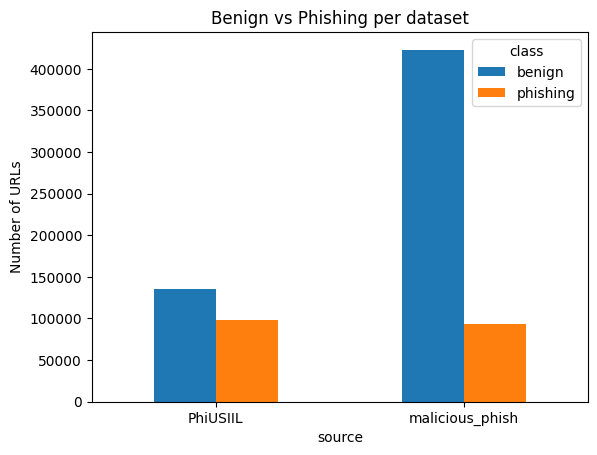

In [7]:
counts = df.groupby(['source', 'class']).size().unstack()   # table: rows = dataset, columns = class
counts.plot(kind='bar', rot=0)                        # bar chart of the counts
plt.title('Benign vs Phishing per dataset')           # chart title
plt.ylabel('Number of URLs')                          # y-axis label
plt.show()                                            # display the chart

                          length  digits  dots
source          class                         
PhiUSIIL        benign      15.2     0.1   1.2
                phishing    37.1     4.3   2.0
malicious_phish benign      56.8     5.6   1.9
                phishing    42.2     3.7   2.1


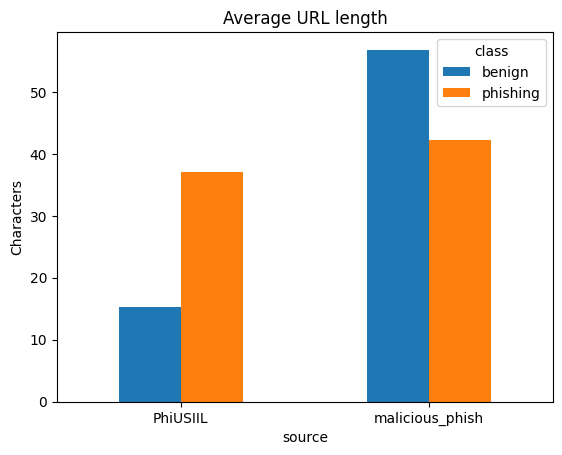

In [8]:
df['length'] = df['url'].str.len()                    # number of characters in each URL
df['digits'] = df['url'].str.count(r'\d')             # number of digits in each URL
df['dots'] = df['url'].str.count(r'\.')               # number of dots (many dots = many subdomains)

print(df.groupby(['source', 'class'])[['length', 'digits', 'dots']].mean().round(1))   # average of each feature per group

df.groupby(['source', 'class'])['length'].mean().unstack().plot(kind='bar', rot=0)     # chart: average URL length
plt.title('Average URL length'); plt.ylabel('Characters'); plt.show()                  # title, label, display

                          has_prefix  has_www  has_path
source          class                                  
PhiUSIIL        benign          1.00     1.00      0.00
                phishing        1.00     0.42      0.59
malicious_phish benign          0.08     0.03      1.00
                phishing        0.26     0.39      0.77


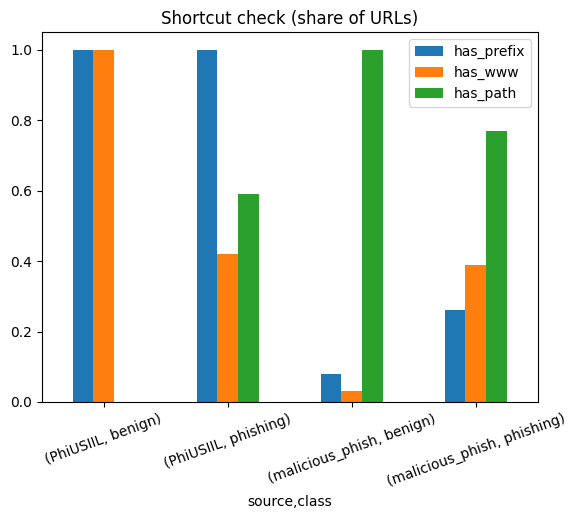

In [9]:
df['has_prefix'] = df['raw_url'].str.match(r'^https?://')        # does the ORIGINAL url start with http(s)://
df['has_www'] = df['raw_url'].str.contains(r'^(?:https?://)?www\.')   # does the ORIGINAL url start with www.
df['has_path'] = df['url'].str.contains('/')                     # does the url have a path (a / after the domain)

check = df.groupby(['source', 'class'])[['has_prefix', 'has_www', 'has_path']].mean().round(2)  # share (0 to 1) of each group
print(check)                                          # compare benign vs phishing rows
check.plot(kind='bar'); plt.title('Shortcut check (share of URLs)'); plt.xticks(rotation=20); plt.show()  # chart of the table

## What to notice
- **Cell 5 is the key one:** if benign and phishing differ a lot in `has_prefix`, `has_www` or `has_path`, a model could cheat using those instead of real clues. That's why we strip `http(s)://` and `www.` first.
- In PhiUSIIL, benign URLs have **no path** at all, while in malicious_phish they almost always do. Mixing both datasets balances this out.